Using device: cuda
Using Colab cache for faster access to the 'surface-crack-detection' dataset.
Dataset path: /kaggle/input/surface-crack-detection
Classes: ['Negative', 'Positive']
Total images in full dataset: 40000
Selected balanced subset size: 3000
Train: 2100 | Val: 450 | Test: 450


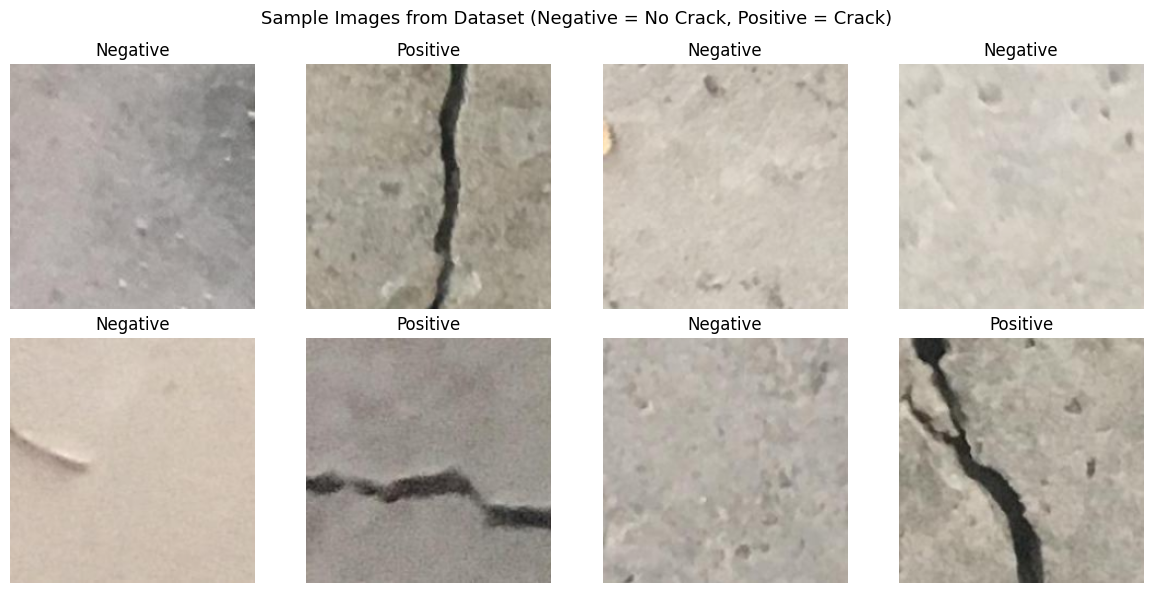

In [1]:
import os
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import kagglehub
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, random_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

dataset_path = kagglehub.dataset_download("arunrk7/surface-crack-detection")
print("Dataset path:", dataset_path)

data_dir = dataset_path
for root, dirs, files in os.walk(dataset_path):
  if "Positive" in dirs and "Negative" in dirs:
    data_dir = root
    break

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

raw_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
print("Classes:", raw_dataset.classes)
print("Total images in full dataset:", len(raw_dataset))

class_0_indices = [
    i for i, (_, label) in enumerate(raw_dataset.samples) if label == 0
][:1500]
class_1_indices = [
    i for i, (_, label) in enumerate(raw_dataset.samples) if label == 1
][:1500]
selected_indices = class_0_indices + class_1_indices
random.shuffle(selected_indices)

dataset = Subset(raw_dataset, selected_indices)
print("Selected balanced subset size:", len(dataset))

total_len = len(dataset)
train_len = int(0.70 * total_len)
val_len = int(0.15 * total_len)
test_len = total_len - train_len - val_len

train_ds, val_ds, test_ds = random_split(
    dataset,
    [train_len, val_len, test_len],
    generator=torch.Generator().manual_seed(SEED),
)

BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
  idx = random.randint(0, len(dataset) - 1)
  img, label = dataset[idx]
  img_np = img.permute(1, 2, 0).numpy() * std + mean
  img_np = np.clip(img_np, 0, 1)
  ax.imshow(img_np)
  ax.set_title(raw_dataset.classes[label])
  ax.axis("off")

plt.suptitle(
    "Sample Images from Dataset (Negative = No Crack, Positive = Crack)",
    fontsize=13,
)
plt.tight_layout()
plt.show()

In [2]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device for model:", device)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()

def evaluate_model(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="binary", zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)
    return avg_loss, acc, prec, rec, f1, all_labels, all_preds, cm

before_loss, before_acc, before_prec, before_rec, before_f1, _, _, _ = evaluate_model(
    model, test_loader, criterion, device
)

print("=== BEFORE TRAINING (Test Set) ===")
print(f"Loss:      {before_loss:.4f}")
print(f"Accuracy:  {before_acc:.4f} ({before_acc*100:.2f}%)")
print(f"Precision: {before_prec:.4f}")
print(f"Recall:    {before_rec:.4f}")
print(f"F1-Score:  {before_f1:.4f}")

Device for model: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


=== BEFORE TRAINING (Test Set) ===
Loss:      0.7143
Accuracy:  0.5356 (53.56%)
Precision: 0.5356
Recall:    1.0000
F1-Score:  0.6975


Epoch [1/4] | Train Loss: 0.0513, Train Acc: 98.00% | Val Loss: 0.0135, Val Acc: 99.78%
Epoch [2/4] | Train Loss: 0.0036, Train Acc: 99.86% | Val Loss: 0.0139, Val Acc: 99.78%
Epoch [3/4] | Train Loss: 0.0015, Train Acc: 100.00% | Val Loss: 0.0149, Val Acc: 99.78%
Epoch [4/4] | Train Loss: 0.0005, Train Acc: 100.00% | Val Loss: 0.0149, Val Acc: 99.78%

Training finished in 77.1 seconds.

=== AFTER TRAINING (Test Set) ===
Loss:      0.0003
Accuracy:  1.0000 (100.00%)
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000

=== BEFORE vs AFTER COMPARISON ===
Metric       | Before     | After     
--------------------------------------
Loss         | 0.7143     | 0.0003    
Accuracy     | 0.5356     | 1.0000    
Precision    | 0.5356     | 1.0000    
Recall       | 1.0000     | 1.0000    
F1-Score     | 0.6975     | 1.0000    


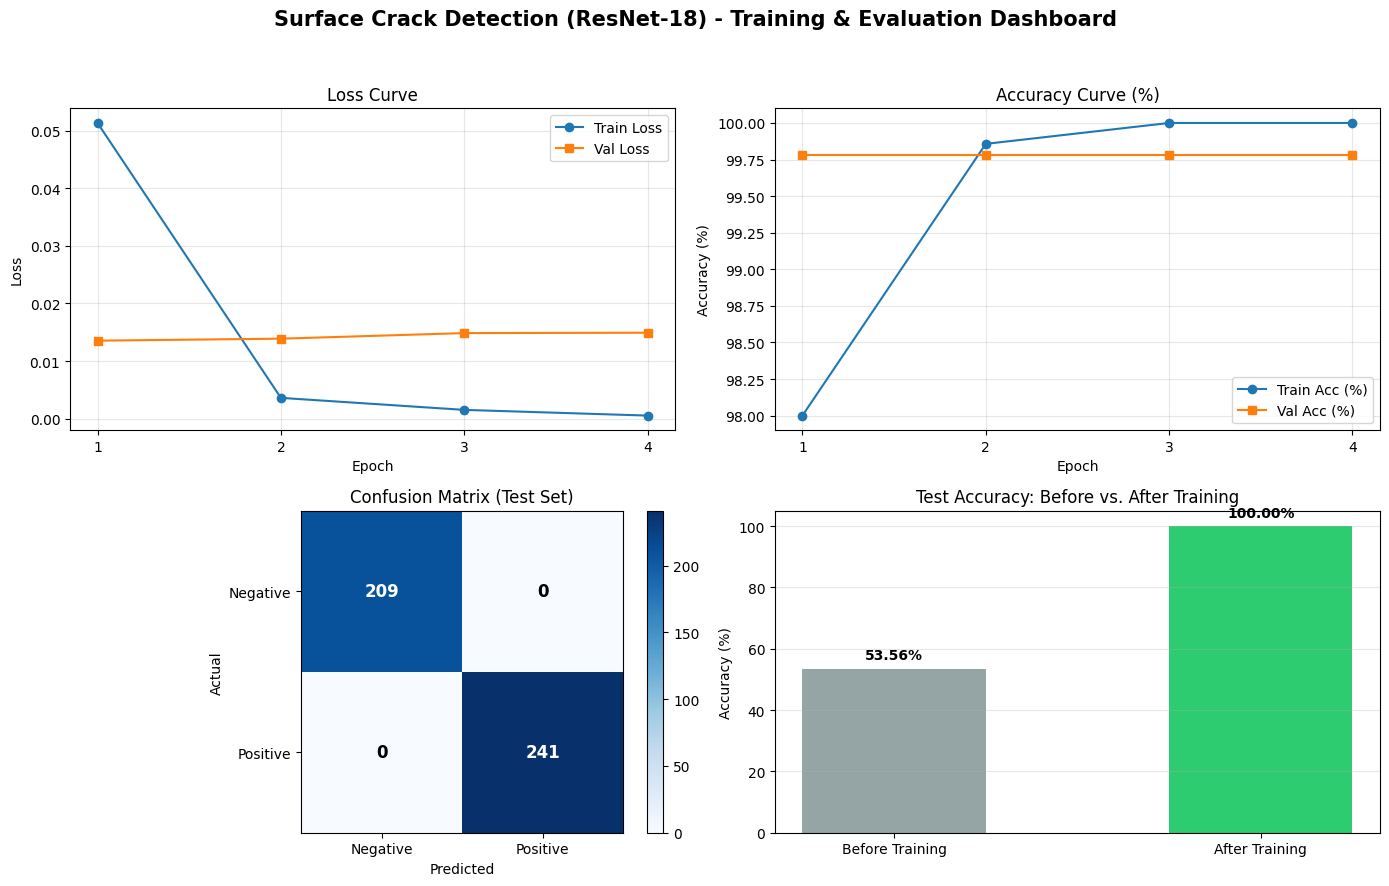

Saved dashboard image as dashboard.png


In [3]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

# 1. إعداد المُحسِّن (Optimizer) وعدد الحقب (Epochs)
EPOCHS = 4
optimizer = optim.Adam(model.parameters(), lr=1e-4)

train_losses, val_losses = [], []
train_accs, val_accs = [], []

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # --- مرحلة التدريب ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- مرحلة التحقق (Validation) ---
    val_loss, val_acc, _, _, _, _, _, _ = evaluate_model(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch [{epoch}/{EPOCHS}] | Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")

elapsed = time.time() - start_time
print(f"\nTraining finished in {elapsed:.1f} seconds.")

# 2. قياس النموذج بعد التدريب على مجموعة الاختبار (Test Set)
after_loss, after_acc, after_prec, after_rec, after_f1, test_labels, test_preds, cm = evaluate_model(
    model, test_loader, criterion, device
)

print("\n=== AFTER TRAINING (Test Set) ===")
print(f"Loss:      {after_loss:.4f}")
print(f"Accuracy:  {after_acc:.4f} ({after_acc*100:.2f}%)")
print(f"Precision: {after_prec:.4f}")
print(f"Recall:    {after_rec:.4f}")
print(f"F1-Score:  {after_f1:.4f}")

# جدول مقارنة واضح (قبل التدريب vs بعد التدريب)
print("\n=== BEFORE vs AFTER COMPARISON ===")
print(f"{'Metric':<12} | {'Before':<10} | {'After':<10}")
print("-" * 38)
print(f"{'Loss':<12} | {before_loss:<10.4f} | {after_loss:<10.4f}")
print(f"{'Accuracy':<12} | {before_acc:<10.4f} | {after_acc:<10.4f}")
print(f"{'Precision':<12} | {before_prec:<10.4f} | {after_prec:<10.4f}")
print(f"{'Recall':<12} | {before_rec:<10.4f} | {after_rec:<10.4f}")
print(f"{'F1-Score':<12} | {before_f1:<10.4f} | {after_f1:<10.4f}")

# 3. إنشاء لوحة نتائج بصرية ثابتة وحفظها كصورة dashboard.png
epochs_range = range(1, EPOCHS + 1)
class_names = raw_dataset.classes  # ['Negative', 'Positive']

fig = plt.figure(figsize=(14, 9))
fig.suptitle("Surface Crack Detection (ResNet-18) - Training & Evaluation Dashboard", fontsize=15, fontweight="bold")

# أ) منحنى الخسارة (Loss Curve)
ax1 = fig.add_subplot(2, 2, 1)
ax1.plot(epochs_range, train_losses, marker="o", label="Train Loss")
ax1.plot(epochs_range, val_losses, marker="s", label="Val Loss")
ax1.set_title("Loss Curve")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_xticks(list(epochs_range))
ax1.legend()
ax1.grid(True, alpha=0.3)

# ب) منحنى الدقة (Accuracy Curve)
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(epochs_range, [a * 100 for a in train_accs], marker="o", label="Train Acc (%)")
ax2.plot(epochs_range, [a * 100 for a in val_accs], marker="s", label="Val Acc (%)")
ax2.set_title("Accuracy Curve (%)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_xticks(list(epochs_range))
ax2.legend()
ax2.grid(True, alpha=0.3)

# ج) مصفوفة الارتباك (Confusion Matrix)
ax3 = fig.add_subplot(2, 2, 3)
im = ax3.imshow(cm, cmap="Blues")
ax3.set_title("Confusion Matrix (Test Set)")
ax3.set_xticks([0, 1])
ax3.set_yticks([0, 1])
ax3.set_xticklabels(class_names)
ax3.set_yticklabels(class_names)
ax3.set_xlabel("Predicted")
ax3.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax3.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)

# د) مقارنة الدقة قبل وبعد التدريب
ax4 = fig.add_subplot(2, 2, 4)
stages = ["Before Training", "After Training"]
accs_pct = [before_acc * 100, after_acc * 100]
bars = ax4.bar(stages, accs_pct, color=["#95a5a6", "#2ecc71"], width=0.5)
ax4.set_title("Test Accuracy: Before vs. After Training")
ax4.set_ylabel("Accuracy (%)")
ax4.set_ylim(0, 105)
for bar in bars:
    h = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width() / 2, h + 2, f"{h:.2f}%", ha="center", va="bottom", fontweight="bold")
ax4.grid(True, axis="y", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("dashboard.png", dpi=150)
plt.show()
print("Saved dashboard image as dashboard.png")

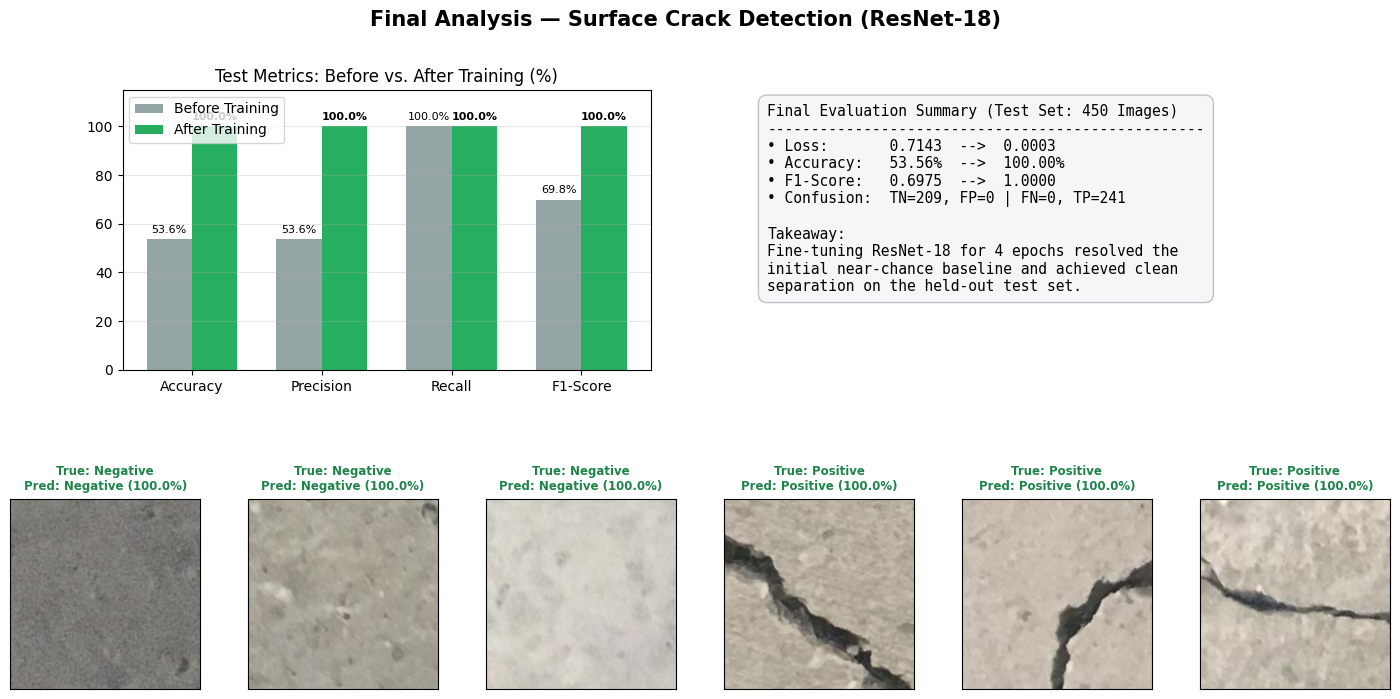

Saved final analysis image as final_analysis.png


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# إعادة إرجاع الصورة إلى نطاقها الطبيعي للعرض
def unnormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
    std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
    img = img_tensor.cpu().numpy() * std + mean
    img = np.clip(img, 0, 1)
    return np.transpose(img, (1, 2, 0))

class_names = raw_dataset.classes  # ['Negative', 'Positive']

# جمع 6 عينات من test_loader للتوضيح البصري (3 Negative و 3 Positive إن أمكن)
model.eval()
neg_samples, pos_samples = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)

        for i in range(images.size(0)):
            item = (images[i], labels[i].item(), preds[i].item(), probs[i][preds[i]].item())
            if labels[i].item() == 0 and len(neg_samples) < 3:
                neg_samples.append(item)
            elif labels[i].item() == 1 and len(pos_samples) < 3:
                pos_samples.append(item)
            if len(neg_samples) == 3 and len(pos_samples) == 3:
                break
        if len(neg_samples) == 3 and len(pos_samples) == 3:
            break

samples = neg_samples + pos_samples

# إنشاء لوحة التحليل النهائي (Final Analysis Figure)
fig = plt.figure(figsize=(15, 8))
fig.suptitle("Final Analysis — Surface Crack Detection (ResNet-18)", fontsize=15, fontweight="bold")

# الجزء العلوي الأيسر: مقارنة المقاييس قبل وبعد التدريب
ax_top_left = fig.add_subplot(2, 2, 1)
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
before_vals = [before_acc * 100, before_prec * 100, before_rec * 100, before_f1 * 100]
after_vals = [after_acc * 100, after_prec * 100, after_rec * 100, after_f1 * 100]

x = np.arange(len(metrics))
width = 0.35
b1 = ax_top_left.bar(x - width/2, before_vals, width, label="Before Training", color="#95a5a6")
b2 = ax_top_left.bar(x + width/2, after_vals, width, label="After Training", color="#27ae60")
ax_top_left.set_title("Test Metrics: Before vs. After Training (%)")
ax_top_left.set_xticks(x)
ax_top_left.set_xticklabels(metrics)
ax_top_left.set_ylim(0, 115)
ax_top_left.legend()
ax_top_left.grid(True, axis="y", alpha=0.3)

for bar in b1:
    h = bar.get_height()
    ax_top_left.text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}%", ha="center", va="bottom", fontsize=8)
for bar in b2:
    h = bar.get_height()
    ax_top_left.text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")

# الجزء العلوي الأيمن: ملخص الأرقام والتحليل
ax_top_right = fig.add_subplot(2, 2, 2)
ax_top_right.axis("off")
summary_text = (
    "Final Evaluation Summary (Test Set: 450 Images)\n"
    "--------------------------------------------------\n"
    f"• Loss:       {before_loss:.4f}  -->  {after_loss:.4f}\n"
    f"• Accuracy:   {before_acc*100:.2f}%  -->  {after_acc*100:.2f}%\n"
    f"• F1-Score:   {before_f1:.4f}  -->  {after_f1:.4f}\n"
    f"• Confusion:  TN={cm[0,0]}, FP={cm[0,1]} | FN={cm[1,0]}, TP={cm[1,1]}\n\n"
    "Takeaway:\n"
    "Fine-tuning ResNet-18 for 4 epochs resolved the\n"
    "initial near-chance baseline and achieved clean\n"
    "separation on the held-out test set."
)
ax_top_right.text(
    0.02, 0.95, summary_text, transform=ax_top_right.transAxes,
    fontsize=10.5, verticalalignment="top", fontfamily="monospace",
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f4f6f7", edgecolor="#bdc3c7")
)

# الجزء السفلي: عينات من صور الاختبار مع توقع النموذج وثقته
gs_bottom = fig.add_gridspec(1, 6, left=0.05, right=0.97, top=0.42, bottom=0.08, wspace=0.25)
for idx, (img_t, true_l, pred_l, conf) in enumerate(samples):
    ax_img = fig.add_subplot(gs_bottom[0, idx])
    ax_img.imshow(unnormalize(img_t))
    ok = (true_l == pred_l)
    color = "#1e8449" if ok else "#c0392b"
    ax_img.set_title(
        f"True: {class_names[true_l]}\nPred: {class_names[pred_l]} ({conf*100:.1f}%)",
        fontsize=8.5, color=color, fontweight="bold"
    )
    ax_img.set_xticks([])
    ax_img.set_yticks([])

plt.savefig("final_analysis.png", dpi=150)
plt.show()
print("Saved final analysis image as final_analysis.png")